# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** Eashan S.G.S  **Index No.:** 220148G

**GitHub repository:** https://github.com/sahas-eashan/EN4554-Assignment-2-CNNs

**Use of AI tools:** Claude (Anthropic) was used to help write and debug the code in this notebook. I have reviewed and understood all of the code and the results.

| Task | Content |
|---|---|
| 1 | Backpropagation from scratch, gradient checks, vanishing gradients |
| 2 | Custom SGD-momentum and Adam, quadratic-bowl trajectories, learning-rate sensitivity |
| 3 | Regularization on 5k images, plain vs residual networks (depth 8 / 20 / 56) |
| 4 | Best CNN with ≤ 500k parameters and ≤ 20 epochs, ablation, single test evaluation |

## Setup

* CIFAR-10 training set split into **45k train / 5k validation** with a fixed seed.
* Per-channel normalization uses the mean and standard deviation of the **45k training split only**.
* The whole dataset is kept on the GPU, and batching and augmentation run on the GPU. This avoids the slow 2-core CPU data loader on Colab.
* The **test set is used only once**, in Task 4.
* Every run's history is cached as JSON (in Google Drive on Colab), so an interrupted session resumes without retraining.

In [1]:
import os, json, time, math, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/EN4554_A2"
    DATA = "/content/data"
else:
    ROOT, DATA = ".", "./data"
RESULTS, FIGS = os.path.join(ROOT, "results"), os.path.join(ROOT, "figures")
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGS, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = True
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

# epochs per experiment
EPOCHS = dict(t1c=20, t2c=10, t3a=60, t3b=30, t4=20)

print("torch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

torch 2.6.0+cu124 | device: cuda | NVIDIA GeForce RTX 3090


In [2]:
def cached(name, fn, force=False):
    """Run fn() once and cache its JSON-serializable result under results/."""
    path = os.path.join(RESULTS, f"{name}.json")
    if os.path.exists(path) and not force:
        with open(path) as f:
            return json.load(f)
    out = fn()
    with open(path, "w") as f:
        json.dump(out, f)
    return out

def savefig(name):
    plt.savefig(os.path.join(FIGS, f"{name}.png"), dpi=150, bbox_inches="tight")

def n_params(model):
    return sum(p.numel() for p in model.parameters())

### Data

In [3]:
train_full = torchvision.datasets.CIFAR10(DATA, train=True, download=True)
test_full = torchvision.datasets.CIFAR10(DATA, train=False, download=True)
CLASSES = train_full.classes

X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float().div(255)
Y_all = torch.tensor(train_full.targets)
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]

MEAN = X_all[tr_idx].mean(dim=(0, 2, 3))
STD = X_all[tr_idx].std(dim=(0, 2, 3))
def normalize(x):
    return (x - MEAN[None, :, None, None]) / STD[None, :, None, None]

Xtr, Ytr = normalize(X_all[tr_idx]).to(DEVICE), Y_all[tr_idx].to(DEVICE)
Xva, Yva = normalize(X_all[va_idx]).to(DEVICE), Y_all[va_idx].to(DEVICE)

# test set: normalized with the TRAINING statistics, kept on the CPU until Task 4
X_test = normalize(torch.tensor(test_full.data).permute(0, 3, 1, 2).float().div(255))
Y_test = torch.tensor(test_full.targets)

print("train", tuple(Xtr.shape), "| val", tuple(Xva.shape), "| test", tuple(X_test.shape))
print("channel mean", MEAN.numpy().round(4), "| channel std", STD.numpy().round(4))
print("train class counts", torch.bincount(Ytr.cpu(), minlength=10).tolist())
print("val   class counts", torch.bincount(Yva.cpu(), minlength=10).tolist())

train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | test (10000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] | channel std [0.2472 0.2436 0.2617]
train class counts [4518, 4492, 4506, 4496, 4468, 4493, 4498, 4494, 4502, 4533]
val   class counts [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


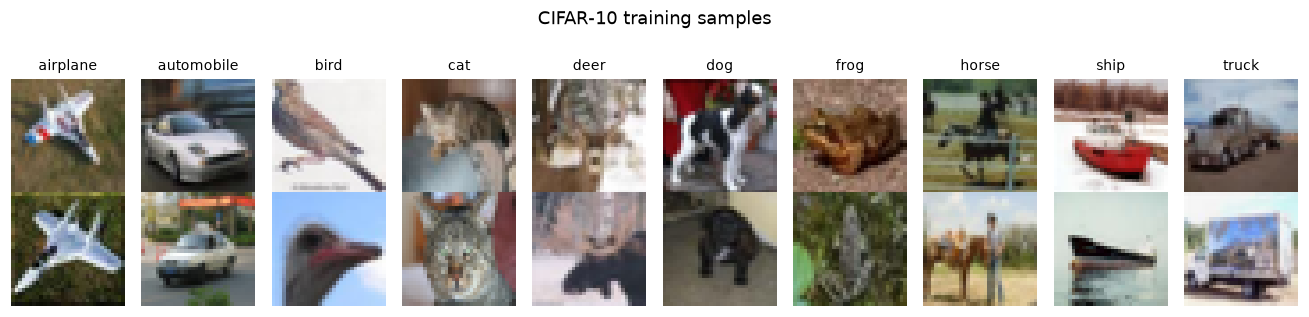

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
raw = X_all[tr_idx]
for c in range(10):
    idx = (Y_all[tr_idx] == c).nonzero()[:2, 0]
    for r in range(2):
        axes[r, c].imshow(raw[idx[r]].permute(1, 2, 0).numpy())
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle("CIFAR-10 training samples", y=1.02); plt.tight_layout(); savefig("samples"); plt.show()

### Shared training utilities
* **Batching:** random mini-batches drawn directly from GPU tensors.
* **Augmentations:** written in PyTorch and applied per batch on the GPU.
  * *Flip + crop:* random horizontal flip, then a random 32×32 crop from the 4-pixel zero-padded image.
  * *Cutout* (own implementation): zero a random 16×16 square in each image. The square may be clipped at the border.
  * *Mixup* (own implementation): $\tilde x=\lambda x_i+(1-\lambda)x_j$ with $\lambda\sim\mathrm{Beta}(\alpha,\alpha)$. The loss is $\lambda\,\mathrm{CE}(y_i)+(1-\lambda)\,\mathrm{CE}(y_j)$.
* **Trainer:** a generic loop that records per-iteration loss and per-epoch train/validation loss and accuracy. Mixed precision is optional and is used only for the larger networks. If the loss becomes non-finite, the run stops and is marked *diverged*.

In [5]:
def batches(X, Y, bs, shuffle=True):
    idx = torch.randperm(len(X)).to(X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], Y[j]

def flip_crop(x, pad=4):
    B, C, H, W = x.shape
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    oy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (oy[:, None] + torch.arange(H, device=x.device))[:, :, None]   # B,H,1
    cols = (ox[:, None] + torch.arange(W, device=x.device))[:, None, :]   # B,1,W
    b = torch.arange(B, device=x.device)[:, None, None]
    return xp[b, :, rows, cols].permute(0, 3, 1, 2).contiguous()          # B,H,W,C -> B,C,H,W

def cutout(x, size=16):
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    yy = torch.arange(H, device=x.device)[None, :, None]
    xx = torch.arange(W, device=x.device)[None, None, :]
    hole = ((yy >= cy - size // 2) & (yy < cy + size // 2) &
            (xx >= cx - size // 2) & (xx < cx + size // 2))
    return x * (~hole)[:, None].to(x.dtype)

def mixup(x, y, alpha):
    lam = float(np.random.beta(alpha, alpha))
    j = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[j], y, y[j], lam

def compose(*fns):
    fns = [f for f in fns if f is not None]
    if not fns:
        return None
    def aug(x):
        for f in fns:
            x = f(x)
        return x
    return aug

In [6]:
@torch.no_grad()
def evaluate(model, X, Y, bs=1000, amp=False):
    model.eval()
    loss, correct = 0.0, 0
    with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=amp and DEVICE.type == "cuda"):
        for i in range(0, len(X), bs):
            out = model(X[i:i + bs].to(DEVICE)).float()
            y = Y[i:i + bs].to(DEVICE)
            loss += F.cross_entropy(out, y, reduction="sum").item()
            correct += (out.argmax(1) == y).sum().item()
    return loss / len(X), correct / len(X)

def train(model, opt, epochs, Xtr, Ytr, Xva, Yva, bs=128, aug=None, mixup_alpha=0.0,
          sched=None, amp=False, label_smoothing=0.0, clean_train_eval=False, log_every=None):
    """Generic training loop. sched: None | 'cosine' | 'warmup_cosine' | 'onecycle' (per-iteration)."""
    amp = amp and DEVICE.type == "cuda"
    scaler = (torch.amp.GradScaler("cuda", enabled=amp) if hasattr(torch.amp, "GradScaler")
              else torch.cuda.amp.GradScaler(enabled=amp))   # older PyTorch (< 2.3)
    steps = epochs * math.ceil(len(Xtr) / bs)
    if sched == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    elif sched == "warmup_cosine":   # linear warm-up for 2 epochs, then cosine decay
        warm = 2 * math.ceil(len(Xtr) / bs)
        scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm
                                                      else 0.5 * (1 + math.cos(math.pi * (s - warm) / (steps - warm))))
    elif sched == "onecycle":
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=[g["lr"] for g in opt.param_groups], total_steps=steps, pct_start=0.25)
    else:
        scheduler = None
    log_every = log_every or max(1, epochs // 5)
    h = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "iter_loss"]}
    h["diverged"], t0 = False, time.time()
    for ep in range(epochs):
        model.train()
        tot_loss, tot_correct, seen, it_losses = 0.0, 0.0, 0, []
        for xb, yb in batches(Xtr, Ytr, bs):
            if aug is not None:
                xb = aug(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
            with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=amp):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = (lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing)
                            + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing))
                else:
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            it_losses.append(loss.detach().float())
            tot_loss += loss.detach().float() * len(yb)
            tot_correct += (out.argmax(1) == yb).sum()
            seen += len(yb)
        train_loss = (tot_loss / seen).item()
        h["iter_loss"] += torch.stack(it_losses).cpu().tolist()
        if not math.isfinite(train_loss):
            h["diverged"] = True
            print(f"  diverged at epoch {ep + 1}")
            break
        h["train_loss"].append(train_loss)
        if clean_train_eval:   # accuracy on un-augmented training images, eval mode
            h["train_acc"].append(evaluate(model, Xtr, Ytr, amp=amp)[1])
        else:                  # running accuracy during the epoch
            h["train_acc"].append((tot_correct / seen).item())
        vl, va = evaluate(model, Xva, Yva, amp=amp)
        h["val_loss"].append(vl); h["val_acc"].append(va)
        if (ep + 1) % log_every == 0 or ep == epochs - 1:
            print(f"  epoch {ep + 1:3d}/{epochs}  train loss {train_loss:.3f}  train acc {h['train_acc'][-1]:.3f}"
                  f"  val acc {va:.3f}  ({time.time() - t0:.0f}s)")
    if h["diverged"]:   # report a diverged run with chance-level validation accuracy
        h["val_acc"].append(evaluate(model, Xva, Yva)[1] if all(
            torch.isfinite(p).all() for p in model.parameters()) else 0.1)
    h["time"] = time.time() - t0
    return h

def smooth(y, k=50):
    y = np.asarray(y, dtype=float)
    if len(y) < k:
        return y
    return np.convolve(y, np.ones(k) / k, mode="valid")

---
# Task 1: Backpropagation

## 1(a) Layers with explicit forward/backward

Each layer caches what its backward pass needs. For an upstream gradient $\delta=\partial\ell/\partial\text{out}$:

* **Linear** $y=xW+b$: $\;\partial\ell/\partial W=x^\top\delta,\;\partial\ell/\partial b=\textstyle\sum_n\delta_n,\;\partial\ell/\partial x=\delta W^\top$
* **ReLU** $y=\max(0,x)$: $\;\partial\ell/\partial x=\delta\odot\mathbb 1[x>0]$
* **Sigmoid** $s=\sigma(x)$ (needed for 1(d)): $\;\partial\ell/\partial x=\delta\odot s(1-s)$
* **Softmax cross-entropy** $\ell=-\frac1N\sum_n\log p_{n,y_n}$: $\;\partial\ell/\partial z=\frac1N(p-\mathrm{onehot}(y))$. It is computed with the log-sum-exp trick for numerical stability.

No autograd is used: the tensors never set `requires_grad`.

In [7]:
class Linear:
    def __init__(self, n_in, n_out, init="he", dtype=torch.float32, device=DEVICE):
        std = math.sqrt(2.0 / n_in) if init == "he" else math.sqrt(2.0 / (n_in + n_out))  # He / Xavier
        self.W = torch.randn(n_in, n_out, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s
    def backward(self, dout):
        return dout * self.s * (1 - self.s)

class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(dim=1, keepdim=True).values             # stability
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act="relu", dtype=torch.float32, device=DEVICE, init=None):
        init = init or ("he" if act == "relu" else "xavier")
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == "relu" else Sigmoid())
        self.criterion = SoftmaxCrossEntropy()
    @property
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]
    def forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x
    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)
    def backward(self):
        d = self.criterion.backward()
        for l in reversed(self.layers):
            d = l.backward(d)
    def params(self):
        return [p for l in self.linears for p in (l.W, l.b)]
    def grads(self):
        return [g for l in self.linears for g in (l.dW, l.db)]

## 1(b) Gradient check

A small MLP (20-16-12-10, ReLU) is checked in **float64** on a random batch of 8 samples. The manual gradients are compared against:
1. **autograd**, using an identical network built from the same weights with PyTorch operations;
2. **centred finite differences**, $\;\frac{\partial\ell}{\partial\theta_i}\approx\frac{\ell(\theta_i+\varepsilon)-\ell(\theta_i-\varepsilon)}{2\varepsilon}$ with $\varepsilon=10^{-6}$, computed for **every** parameter.

The relative error is $\;\|g_1-g_2\|_2/(\|g_1\|_2+\|g_2\|_2)$.

In [8]:
set_seed()
gnet = MLP([20, 16, 12, 10], act="relu", dtype=torch.float64, device="cpu")
xg = torch.randn(8, 20, dtype=torch.float64)
yg = torch.randint(0, 10, (8,))

loss_manual = gnet.loss(xg, yg)
gnet.backward()
g_manual = [g.clone() for g in gnet.grads()]

# autograd on the same weights
leaf = [p.clone().requires_grad_(True) for p in gnet.params()]
h = xg
for i in range(0, len(leaf), 2):
    h = h @ leaf[i] + leaf[i + 1]
    if i < len(leaf) - 2:
        h = torch.relu(h)
loss_auto = F.cross_entropy(h, yg)
loss_auto.backward()
g_auto = [p.grad for p in leaf]

# centred finite differences over every parameter
def finite_diff(net, x, y, eps=1e-6):
    out = []
    for p in net.params():
        flat, g = p.view(-1), torch.zeros(p.numel(), dtype=p.dtype)
        for i in range(flat.numel()):
            old = flat[i].item()
            flat[i] = old + eps; lp = net.loss(x, y).item()
            flat[i] = old - eps; lm = net.loss(x, y).item()
            flat[i] = old
            g[i] = (lp - lm) / (2 * eps)
        out.append(g.view_as(p))
    return out
g_fd = finite_diff(gnet, xg, yg)

def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-30)).item()

names = [f"{k}{i + 1}" for i in range(3) for k in ("W", "b")]
gc = pd.DataFrame({
    "parameter": names,
    "shape": [tuple(g.shape) for g in g_manual],
    "rel. err vs autograd": [rel_err(a, b) for a, b in zip(g_manual, g_auto)],
    "allclose (autograd)": [torch.allclose(a, b) for a, b in zip(g_manual, g_auto)],
    "rel. err vs finite diff.": [rel_err(a, b) for a, b in zip(g_manual, g_fd)],
    "allclose (finite diff.)": [torch.allclose(a, b, rtol=1e-5, atol=1e-7) for a, b in zip(g_manual, g_fd)],
})
print(f"loss: manual {loss_manual.item():.12f} | autograd {loss_auto.item():.12f}")
display(gc.style.format({"rel. err vs autograd": "{:.2e}", "rel. err vs finite diff.": "{:.2e}"}).hide(axis="index"))

loss: manual 3.757791109124 | autograd 3.757791109124


parameter,shape,rel. err vs autograd,allclose (autograd),rel. err vs finite diff.,allclose (finite diff.)
W1,"(20, 16)",4.57e-17,True,6.13e-10,True
b1,"(16,)",5.98e-17,True,5.00e-10,True
W2,"(16, 12)",1.94e-17,True,3.99e-10,True
b2,"(12,)",2.54e-17,True,3.51e-10,True
W3,"(12, 10)",1.31e-17,True,4.40e-10,True
b3,"(10,)",2.31e-17,True,1.00e-09,True


**Interpretation.**
* **Against autograd:** the manual gradients agree to machine precision. The relative errors are $1$–$6\times10^{-17}$, the two losses are identical to 12 digits, and `torch.allclose` is `True` for every parameter.
* **Against finite differences:** the relative errors are $3.5\times10^{-10}$–$1.0\times10^{-9}$. That is the expected size of the $O(\varepsilon^2)$ truncation error plus round-off for $\varepsilon=10^{-6}$ in float64, and `allclose` also passes everywhere.
* The finite-difference check uses no framework at all. It therefore validates the backward-pass derivations themselves, not just consistency with PyTorch.

## 1(c) Training the from-scratch MLP with SGD

The MLP is 3072 → 512 → 256 → 10 with ReLU and He initialization. It is trained on flattened, normalized images using plain mini-batch SGD (batch 128, constant learning rate 0.02, 20 epochs). The update $\theta\leftarrow\theta-\eta\,\nabla\theta$ is written by hand.

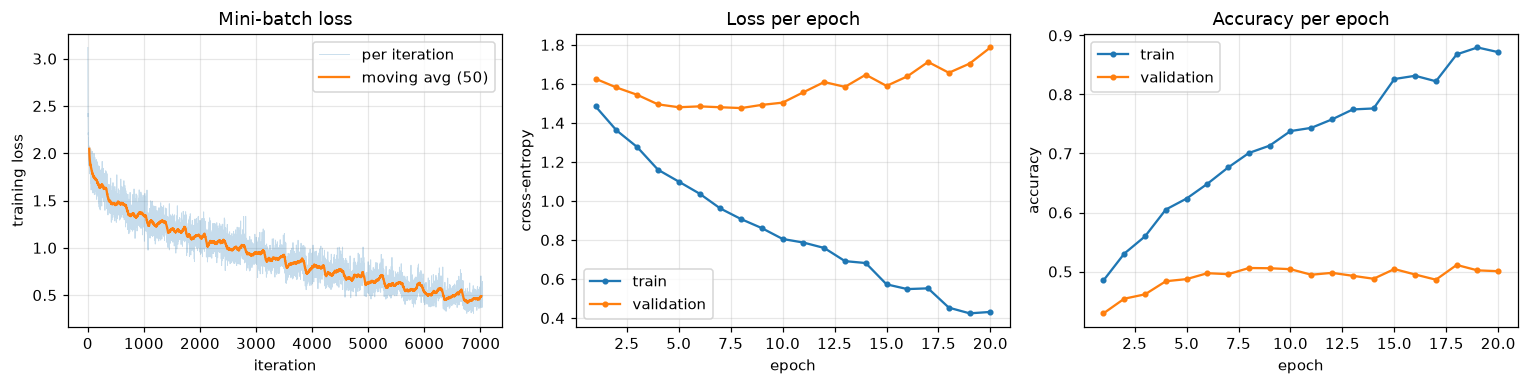

final validation accuracy: 0.5006 | best: 0.5112 (epoch 18)


In [9]:
def train_manual_mlp(sizes, epochs, lr, bs=128):
    set_seed()
    net = MLP(sizes, act="relu", device=DEVICE)
    Xf_tr, Xf_va = Xtr.reshape(len(Xtr), -1), Xva.reshape(len(Xva), -1)
    def eval_split(X, Y):
        losses, correct = [], 0
        for i in range(0, len(X), 1000):
            z = net.forward(X[i:i + 1000])
            losses.append(net.criterion.forward(z, Y[i:i + 1000]) * len(z))
            correct += (z.argmax(1) == Y[i:i + 1000]).sum().item()
        return (torch.stack(losses).sum() / len(X)).item(), correct / len(X)
    h = {k: [] for k in ["iter_loss", "train_loss", "train_acc", "val_loss", "val_acc"]}
    for ep in range(epochs):
        its = []
        for xb, yb in batches(Xf_tr, Ytr, bs):
            its.append(net.loss(xb, yb))
            net.backward()
            for p, g in zip(net.params(), net.grads()):
                p -= lr * g                        # plain SGD step (in place)
        h["iter_loss"] += torch.stack(its).cpu().tolist()
        tl, ta = eval_split(Xf_tr, Ytr); vl, va = eval_split(Xf_va, Yva)
        for k, v in zip(["train_loss", "train_acc", "val_loss", "val_acc"], [tl, ta, vl, va]):
            h[k].append(v)
        if (ep + 1) % 5 == 0 or ep == epochs - 1:
            print(f"  epoch {ep + 1:2d}  train loss {tl:.3f}  train acc {ta:.3f}  val loss {vl:.3f}  val acc {va:.3f}")
    return h

h1c = cached("t1c_mlp", lambda: train_manual_mlp([3072, 512, 256, 10], EPOCHS["t1c"], lr=0.02))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(h1c["iter_loss"], alpha=0.25, lw=0.6, label="per iteration")
ax[0].plot(np.arange(len(smooth(h1c["iter_loss"]))) + 25, smooth(h1c["iter_loss"]), label="moving avg (50)")
ax[0].set(xlabel="iteration", ylabel="training loss", title="Mini-batch loss"); ax[0].legend()
ep = np.arange(1, len(h1c["train_loss"]) + 1)
ax[1].plot(ep, h1c["train_loss"], "o-", ms=3, label="train"); ax[1].plot(ep, h1c["val_loss"], "o-", ms=3, label="validation")
ax[1].set(xlabel="epoch", ylabel="cross-entropy", title="Loss per epoch"); ax[1].legend()
ax[2].plot(ep, h1c["train_acc"], "o-", ms=3, label="train"); ax[2].plot(ep, h1c["val_acc"], "o-", ms=3, label="validation")
ax[2].set(xlabel="epoch", ylabel="accuracy", title="Accuracy per epoch"); ax[2].legend()
plt.tight_layout(); savefig("t1c_mlp"); plt.show()
best = int(np.argmax(h1c["val_acc"]))
print(f"final validation accuracy: {h1c['val_acc'][-1]:.4f} | best: {h1c['val_acc'][best]:.4f} (epoch {best + 1})")

**Interpretation.**
* **Mini-batch loss:** it drops quickly from 2.3 to about 1.5 in the first epoch, then decreases steadily to about 0.5. The noise around the moving average is the sampling noise of SGD.
* **Validation accuracy:** best **51.1 %** (epoch 18), final **50.1 %**. This is typical for a fully connected network on raw pixels.
  * Flattening the image discards spatial structure.
  * The network has no weight sharing or translation invariance, so it must learn every pattern separately at every position.
* **Clear overfitting:**
  * The validation loss reaches its minimum (about 1.47) around epochs 5–8 and then rises to 1.78.
  * Over the same period the training loss keeps falling to 0.43, and training accuracy climbs to 87 %, while validation accuracy stays flat around 50 %.
  * The 1.7M-parameter MLP is memorizing the training set. Early stopping at the validation-loss minimum, or regularization, would be needed.

## 1(d) Gradient norms at initialization: sigmoid vs ReLU (10-layer MLP)

The network is 3072 → 9 hidden layers of width 256 → 10 (10 linear layers). The sigmoid network uses Xavier initialization and the ReLU network uses He initialization, i.e. each activation gets its standard initialization. One forward/backward pass on 512 training images gives $\|\partial\ell/\partial W_l\|_F$ for every layer.

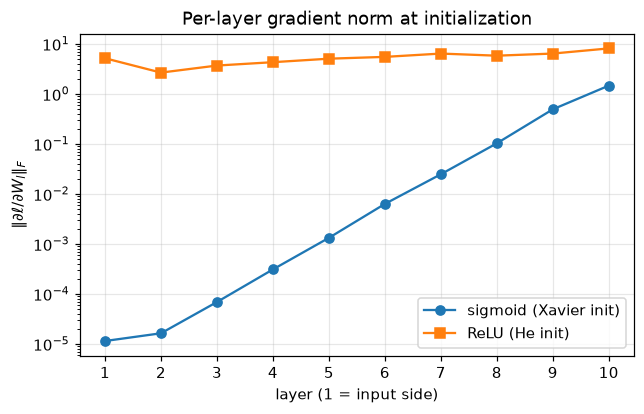

layer,1,2,3,4,5,6,7,8,9,10
sigmoid,1.15e-05,1.64e-05,6.89e-05,3.09e-04,1.32e-03,6.30e-03,2.47e-02,1.03e-01,4.91e-01,1.46e+00
relu,5.16e+00,2.66e+00,3.69e+00,4.30e+00,5.06e+00,5.49e+00,6.40e+00,5.80e+00,6.40e+00,8.11e+00


sigmoid : layer-1 / layer-10 gradient-norm ratio = 7.84e-06
relu    : layer-1 / layer-10 gradient-norm ratio = 6.36e-01


In [10]:
def layer_grad_norms(act, depth=10, width=256, n=512):
    set_seed()
    net = MLP([3072] + [width] * (depth - 1) + [10], act=act, device=DEVICE)
    net.loss(Xtr[:n].reshape(n, -1), Ytr[:n])
    net.backward()
    return [l.dW.norm().item() for l in net.linears]

gn = {act: layer_grad_norms(act) for act in ["sigmoid", "relu"]}
layers = np.arange(1, 11)
plt.figure(figsize=(6.5, 3.8))
plt.semilogy(layers, gn["sigmoid"], "o-", label="sigmoid (Xavier init)")
plt.semilogy(layers, gn["relu"], "s-", label="ReLU (He init)")
plt.xticks(layers); plt.xlabel("layer (1 = input side)"); plt.ylabel(r"$\|\partial \ell / \partial W_l\|_F$")
plt.title("Per-layer gradient norm at initialization"); plt.legend()
savefig("t1d_gradnorms"); plt.show()
display(pd.DataFrame(gn, index=pd.Index(layers, name="layer")).T.style.format("{:.2e}"))
for act in gn:
    print(f"{act:8s}: layer-1 / layer-10 gradient-norm ratio = {gn[act][0] / gn[act][-1]:.2e}")

**Interpretation.**
* **Sigmoid:** the gradient norm falls by about **five orders of magnitude** from the last layer (1.46) to the first layer ($1.2\times10^{-5}$). That is a layer-1 / layer-10 ratio of $7.8\times10^{-6}$, the classic **vanishing-gradient** problem.
  * Each backward step through a sigmoid layer multiplies the gradient by $\sigma'(z)\le 0.25$, and by $W^\top$, whose gain under Xavier initialization is about 1.
  * The gradient therefore shrinks by a factor of roughly 4 per layer, which is the straight line on the log plot. The early layers would barely learn.
* **ReLU:** the gradient norm stays within about **2.7–8.1 across all 10 layers** (ratio 0.64).
  * $\mathrm{ReLU}'\in\{0,1\}$, so about half the units pass the gradient through unchanged.
  * He initialization ($\mathrm{Var}(W)=2/n_\text{in}$) is chosen to compensate exactly for that factor $\tfrac12$, so the gradient variance is preserved with depth.
* This is why deep networks use ReLU-type activations with He initialization.

---
# Task 2: Optimizers

## 2(a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses

For a gradient $g_t$ (with L2 weight decay, $g_t\leftarrow g_t+\lambda\theta$):

* **SGD with momentum** (PyTorch convention, no dampening): $\;b_t=\mu\,b_{t-1}+g_t,\;\theta\leftarrow\theta-\eta\,b_t$, with $b_1=g_1$.
* **Adam** with bias correction:
  * moment estimates: $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\;v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2$
  * bias-corrected moments: $\hat m_t=m_t/(1-\beta_1^t),\;\hat v_t=v_t/(1-\beta_2^t)$
  * update: $\theta\leftarrow\theta-\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$

In [11]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if "buf" not in state:
                        state["buf"] = g.clone()
                    else:
                        state["buf"].mul_(mu).add_(g)
                    g = state["buf"]
                p.add_(g, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad.add(p, alpha=wd)
                state = self.state[p]
                if not state:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = m / (1 - b1 ** t)
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

**Equivalence test.** Two copies of the same small network (float64) are trained side by side for 200 steps, on the *same* random mini-batches. One copy uses my optimizer and the other uses the `torch.optim` reference. Parameters are compared after every step.

In [12]:
def compare(make_mine, make_ref, steps=200):
    set_seed()
    ref = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 5)).double()
    mine = copy.deepcopy(ref)
    o_mine, o_ref = make_mine(mine.parameters()), make_ref(ref.parameters())
    worst = 0.0
    for _ in range(steps):
        x = torch.randn(32, 20, dtype=torch.float64); y = torch.randint(0, 5, (32,))
        for model, opt in ((mine, o_mine), (ref, o_ref)):
            opt.zero_grad(); F.cross_entropy(model(x), y).backward(); opt.step()
        worst = max(worst, max((a - b).abs().max().item() for a, b in zip(mine.parameters(), ref.parameters())))
    match = all(torch.allclose(a, b) for a, b in zip(mine.parameters(), ref.parameters()))
    return worst, match

tests = {
    "SGD (lr=0.1)": (lambda p: MySGD(p, lr=0.1), lambda p: torch.optim.SGD(p, lr=0.1)),
    "SGD momentum (lr=0.05, mu=0.9, wd=1e-3)": (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3),
                                               lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=1e-3)),
    "Adam (lr=1e-2)": (lambda p: MyAdam(p, lr=1e-2), lambda p: torch.optim.Adam(p, lr=1e-2)),
    "Adam (lr=1e-3, betas=(0.8,0.99), wd=1e-3)": (lambda p: MyAdam(p, lr=1e-3, betas=(0.8, 0.99), weight_decay=1e-3),
                                                  lambda p: torch.optim.Adam(p, lr=1e-3, betas=(0.8, 0.99), weight_decay=1e-3)),
}
rows = []
for name, (mk_mine, mk_ref) in tests.items():
    worst, match = compare(mk_mine, mk_ref)
    rows.append({"optimizer": name, "max |θ_mine − θ_torch| over 200 steps": f"{worst:.1e}", "torch.allclose": match})
display(pd.DataFrame(rows).style.hide(axis="index"))

optimizer,max |θ_mine − θ_torch| over 200 steps,torch.allclose
SGD (lr=0.1),0.0e+00,True
"SGD momentum (lr=0.05, mu=0.9, wd=1e-3)",0.0e+00,True
Adam (lr=1e-2),4.4e-16,True
"Adam (lr=1e-3, betas=(0.8,0.99), wd=1e-3)",8.3e-17,True


**Interpretation.**
* Both custom optimizers reproduce PyTorch's implementations to within floating-point round-off over 200 steps, and `torch.allclose` is `True` for all four configurations.
  * The SGD variants (with and without momentum and weight decay) match **bit-for-bit**: the difference is 0.
  * Adam differs by at most $4.4\times10^{-16}$. PyTorch folds the bias corrections into the step size and the denominator, which is algebraically identical to the textbook form used here, so only round-off differs.

## 2(b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$

The Hessian is $\mathrm{diag}(1,50)$, so the condition number is $\kappa=50$: the bowl is 50× steeper along $y$ than along $x$. All three methods start from $(-4.5,\,1.0)$ and run for 100 steps of the custom optimizers from 2(a):
* SGD and SGD + momentum ($\mu=0.9$) both use $\eta=0.03$. Gradient descent is stable only for $\eta<2/50=0.04$.
* Adam uses $\eta=0.3$.

The gradient here is exact, so "SGD" is plain gradient descent.

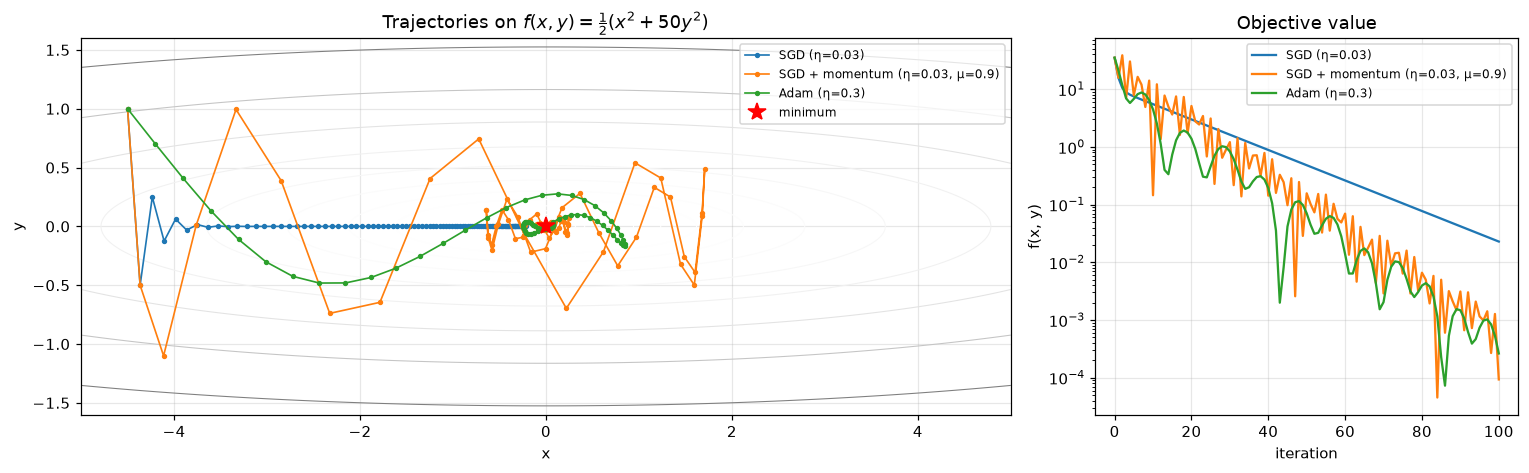

SGD (η=0.03)                     final point (-2.14e-01,  7.89e-31)  f = 2.29e-02
SGD + momentum (η=0.03, μ=0.9)   final point ( 1.11e-02, -1.12e-03)  f = 9.34e-05
Adam (η=0.3)                     final point (-1.98e-02, -1.64e-03)  f = 2.63e-04


In [13]:
def f_xy(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)

def trajectory(make_opt, start=(-4.5, 1.0), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path, vals = [p.detach().clone()], [f_xy(p).item()]
    for _ in range(steps):
        opt.zero_grad(); f_xy(p).backward(); opt.step()
        path.append(p.detach().clone()); vals.append(f_xy(p).item())
    return torch.stack(path).numpy(), np.array(vals)

runs2b = {
    "SGD (η=0.03)": trajectory(lambda p: MySGD(p, lr=0.03)),
    "SGD + momentum (η=0.03, μ=0.9)": trajectory(lambda p: MySGD(p, lr=0.03, momentum=0.9)),
    "Adam (η=0.3)": trajectory(lambda p: MyAdam(p, lr=0.3)),
}
xs, ys = np.meshgrid(np.linspace(-5, 5, 400), np.linspace(-1.6, 1.6, 400))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].contour(xs, ys, 0.5 * (xs ** 2 + 50 * ys ** 2), levels=np.logspace(-2, 2, 18), cmap="Greys", linewidths=0.7)
for (name, (path, _)), c in zip(runs2b.items(), ["C0", "C1", "C2"]):
    ax[0].plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1.1, color=c, label=name)
ax[0].plot(0, 0, "r*", ms=12, label="minimum")
ax[0].set(xlabel="x", ylabel="y", title=r"Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$")
ax[0].legend(loc="upper right", fontsize=8)
for (name, (_, vals)), c in zip(runs2b.items(), ["C0", "C1", "C2"]):
    ax[1].semilogy(vals, color=c, label=name)
ax[1].set(xlabel="iteration", ylabel="f(x, y)", title="Objective value"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("t2b_trajectories"); plt.show()
for name, (path, vals) in runs2b.items():
    print(f"{name:32s} final point ({path[-1, 0]: .2e}, {path[-1, 1]: .2e})  f = {vals[-1]:.2e}")

**Interpretation.**
* **SGD (gradient descent):** the step size is limited by the steep $y$ direction.
  * Along $y$ each step multiplies the error by $1-50\eta=-0.5$. The first few steps zig-zag across the valley, then $y$ quickly reaches 0.
  * Along the flat $x$ direction the factor is only $1-\eta=0.97$, so the iterate creeps towards the minimum. After 100 steps it is still at $x=-0.21$ with $f=2.3\times10^{-2}$.
  * Ill-conditioning ($\kappa=50$) makes plain gradient descent slow, because a learning rate that is safe for the steep direction is tiny for the flat one.
* **SGD + momentum:** the velocity accumulates the consistent $x$-gradient, giving roughly $1/(1-\mu)=10\times$ faster progress along the valley. It ends with $f=9.3\times10^{-5}$, about 250× lower than SGD.
  * With $\mu=0.9$ the system is strongly **under-damped**. The trajectory swings far past the minimum in both $x$ (out to $x\approx1.7$) and $y$, and the objective oscillates instead of decreasing monotonically.
* **Adam:** its first steps are about $\eta$ in *both* coordinates, i.e. a diagonal move along $-\mathrm{sign}(\nabla f)$. This is because each coordinate is normalized by its own gradient RMS, so the steep $y$ direction no longer dictates the step.
  * The path is much smoother than momentum's.
  * It overshoots to $x\approx0.85$ while $\hat m$ decays, then spirals in to $f=2.6\times10^{-4}$.
* **Summary:** momentum and adaptive scaling are two different fixes for ill-conditioning. Both beat plain gradient descent by about two orders of magnitude in 100 steps.

## 2(c) Optimizer comparison on a small CNN

The small CNN is conv32-conv32-pool-conv64-conv64-pool-conv128-pool, followed by FC256 and FC10, with **no batch norm**. Without batch norm the optimizer's behaviour is not masked by normalization.
* Each optimizer from 2(a) is trained at $\eta\in\{10^{-3},10^{-2},10^{-1}\}$ for 10 epochs on the 45k training split.
* Batch size is 128, with a constant learning rate and no augmentation.
* Validation accuracy is reported at the last epoch. Diverged runs are counted at chance level.

In [14]:
class SmallCNN(nn.Module):
    def __init__(self, bn=False, dropout=0.0, c=32):
        super().__init__()
        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.ReLU(inplace=True)]
        self.features = nn.Sequential(*block(3, c), *block(c, c), nn.MaxPool2d(2),
                                      *block(c, 2 * c), *block(2 * c, 2 * c), nn.MaxPool2d(2),
                                      *block(2 * c, 4 * c), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(4 * c * 16, 256),
                                  nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(256, 10))
    def forward(self, x):
        return self.head(self.features(x))

print("SmallCNN parameters:", f"{n_params(SmallCNN()):,}")

LRS = [1e-3, 1e-2, 1e-1]
OPTIMIZERS = {
    "SGD": lambda p, lr: MySGD(p, lr=lr),
    "SGD+momentum": lambda p, lr: MySGD(p, lr=lr, momentum=0.9),
    "Adam": lambda p, lr: MyAdam(p, lr=lr),
}
res2c = {}
for oname, make in OPTIMIZERS.items():
    for lr in LRS:
        def run(make=make, lr=lr):
            set_seed()
            model = SmallCNN(bn=False).to(DEVICE)
            return train(model, make(model.parameters(), lr), EPOCHS["t2c"], Xtr, Ytr, Xva, Yva, bs=128)
        print(f"{oname}, lr={lr:g}")
        res2c[(oname, lr)] = cached(f"t2c_{oname}_{lr:g}", run)

SmallCNN parameters: 666,538
SGD, lr=0.001
SGD, lr=0.01
SGD, lr=0.1
SGD+momentum, lr=0.001
SGD+momentum, lr=0.01
SGD+momentum, lr=0.1
Adam, lr=0.001
Adam, lr=0.01
Adam, lr=0.1


,SGD,SGD+momentum,Adam
learning rate,,,
0.001,0.136,0.476,0.751
0.01,0.438,0.749,0.524
0.1,0.680,0.552,0.100


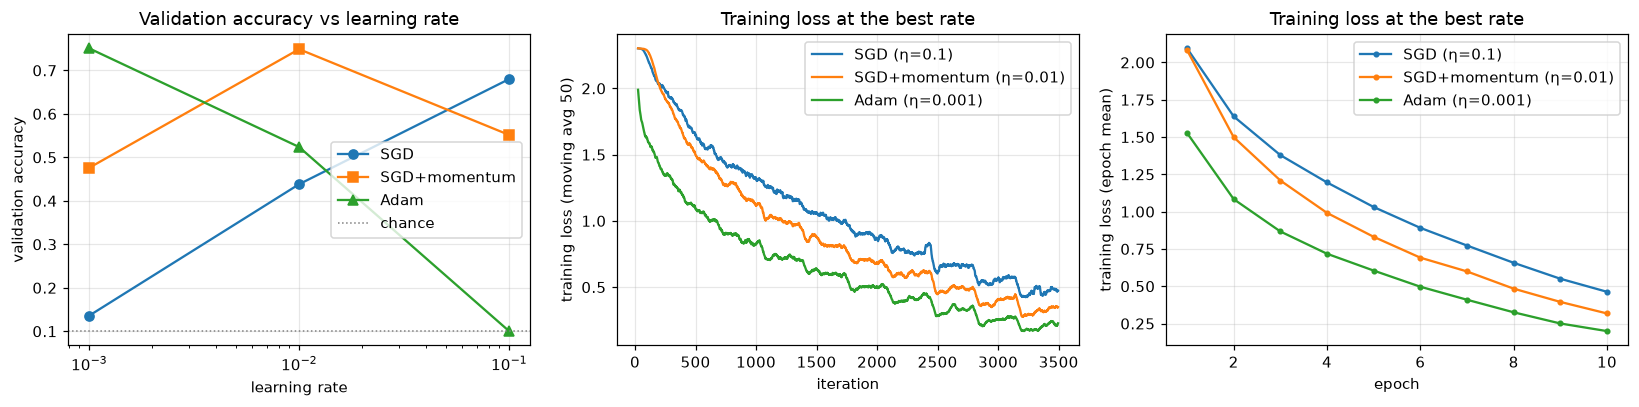

best learning rate per optimizer: {'SGD': 0.1, 'SGD+momentum': 0.01, 'Adam': 0.001}
diverged runs: none


In [15]:
tab = pd.DataFrame({o: [res2c[(o, lr)]["val_acc"][-1] for lr in LRS] for o in OPTIMIZERS},
                   index=pd.Index([f"{lr:g}" for lr in LRS], name="learning rate"))
display(tab.style.format("{:.3f}").highlight_max(axis=0, props="font-weight:bold"))
best_lr = {o: LRS[int(np.argmax(tab[o].values))] for o in OPTIMIZERS}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for o, mk in zip(OPTIMIZERS, ["o", "s", "^"]):
    ax[0].semilogx(LRS, tab[o].values, mk + "-", label=o)
ax[0].axhline(0.1, color="gray", ls=":", lw=1, label="chance")
ax[0].set(xlabel="learning rate", ylabel="validation accuracy", title="Validation accuracy vs learning rate")
ax[0].legend()
for o in OPTIMIZERS:
    hh = res2c[(o, best_lr[o])]
    ax[1].plot(np.arange(len(smooth(hh["iter_loss"]))) + 25, smooth(hh["iter_loss"]), label=f"{o} (η={best_lr[o]:g})")
    ax[2].plot(np.arange(1, len(hh["train_loss"]) + 1), hh["train_loss"], "o-", ms=3, label=f"{o} (η={best_lr[o]:g})")
ax[1].set(xlabel="iteration", ylabel="training loss (moving avg 50)", title="Training loss at the best rate")
ax[2].set(xlabel="epoch", ylabel="training loss (epoch mean)", title="Training loss at the best rate")
ax[1].legend(); ax[2].legend()
plt.tight_layout(); savefig("t2c_optimizers"); plt.show()
print("best learning rate per optimizer:", best_lr)
print("diverged runs:", [f"{o} η={lr:g}" for (o, lr), hh in res2c.items() if hh["diverged"]] or "none")

**Interpretation.**

| optimizer | $\eta=10^{-3}$ | $\eta=10^{-2}$ | $\eta=10^{-1}$ |
|---|---|---|---|
| SGD | 13.6 % | 43.8 % | **68.0 %** |
| SGD + momentum | 47.6 % | **74.9 %** | 55.2 % |
| Adam | **75.1 %** | 52.4 % | 10.0 % |

* **Each optimizer has its own sweet spot,** about one decade lower for every step from SGD → momentum → Adam:
  * Momentum's effective step is about $\eta/(1-\mu)=10\eta$, so it wants a 10× smaller rate than SGD.
  * Adam normalizes every update to about $\eta$ per parameter, so it needs the smallest rate.
* **Sensitivity is high for all three:** moving one decade away from the best rate costs 25–65 percentage points.
  * Plain SGD at $10^{-3}$ barely leaves chance level in 10 epochs (13.6 %).
  * Adam at $10^{-1}$ never learns. Its loss stays at $\ln 10\approx2.30$ and accuracy at chance (10 %), because the huge per-parameter steps immediately push the ReLUs into a dead or saturated state. It does not produce NaN.
  * Momentum at $10^{-1}$ is unstable but still reaches 55 %.
  * SGD's best rate sits at the edge of the grid, so it would probably improve further at a higher rate.
* **Best rates:** Adam ($10^{-3}$) and momentum ($10^{-2}$) both reach about **75 %**, clearly ahead of plain SGD (68 %).
* **Training loss at the best rate:** Adam decreases the fastest throughout, then momentum, then plain SGD. Adaptive and momentum methods converge faster per iteration *if* their learning rate is tuned.

---
# Task 3: Regularization and residual connections

## 3(a) Regularization on 5k training images

**Data:** a class-balanced subset of **5,000 training images** (500 per class, seeded) from the 45k split. Evaluation uses the 5k validation split.

**Model and training:**
* The SmallCNN from 2(c) **with batch norm**.
* SGD with momentum 0.9, learning rate 0.05 with cosine decay, batch size 128, 60 epochs.

**Settings compared:**

| setting | change from baseline |
|---|---|
| baseline | none |
| weight decay | L2 penalty $\lambda=10^{-3}$ |
| dropout | $p=0.5$ before both fully connected layers |
| flip+crop | random horizontal flip + random crop with 4-pixel padding |
| cutout | one random 16×16 hole per image (own implementation) |
| mixup | $\alpha=0.4$ (own implementation) |
| all combined | all of the above |

*Train accuracy* is measured in eval mode on the **clean** (un-augmented) training images, so it is comparable across settings, including mixup.

In [16]:
g5k = torch.Generator().manual_seed(SEED)
sub = torch.cat([(Ytr.cpu() == c).nonzero()[:, 0][torch.randperm(int((Ytr.cpu() == c).sum()), generator=g5k)[:500]]
                 for c in range(10)])
X5k, Y5k = Xtr[sub.to(DEVICE)], Ytr[sub.to(DEVICE)]
print("small training set:", tuple(X5k.shape), "| class counts:", torch.bincount(Y5k.cpu()).tolist())

REG = {
    "baseline":     dict(),
    "weight decay": dict(wd=1e-3),
    "dropout":      dict(dropout=0.5),
    "flip+crop":    dict(flipcrop=True),
    "cutout":       dict(cutout=True),
    "mixup":        dict(mixup=0.4),
    "all combined": dict(wd=1e-3, dropout=0.5, flipcrop=True, cutout=True, mixup=0.4),
}

def run_reg(cfg):
    set_seed()
    model = SmallCNN(bn=True, dropout=cfg.get("dropout", 0.0)).to(DEVICE)
    opt = MySGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get("wd", 0.0))
    aug = compose(flip_crop if cfg.get("flipcrop") else None, cutout if cfg.get("cutout") else None)
    return train(model, opt, EPOCHS["t3a"], X5k, Y5k, Xva, Yva, bs=128, aug=aug,
                 mixup_alpha=cfg.get("mixup", 0.0), sched="cosine", clean_train_eval=True, log_every=20)

res3a = {}
for name, cfg in REG.items():
    print(name)
    res3a[name] = cached(f"t3a_{name.replace(' ', '_').replace('+', '')}", lambda cfg=cfg: run_reg(cfg))

small training set: (5000, 3, 32, 32) | class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
baseline
weight decay
dropout
flip+crop
cutout
mixup
all combined


,train acc,val acc,gap (train − val),best val acc
setting,,,,
baseline,1.000,0.665,0.335,0.665
weight decay,1.000,0.669,0.331,0.672
dropout,0.939,0.673,0.266,0.677
flip+crop,0.933,0.747,0.186,0.750
cutout,0.999,0.701,0.298,0.703
mixup,0.999,0.674,0.325,0.677
all combined,0.673,0.628,0.045,0.634


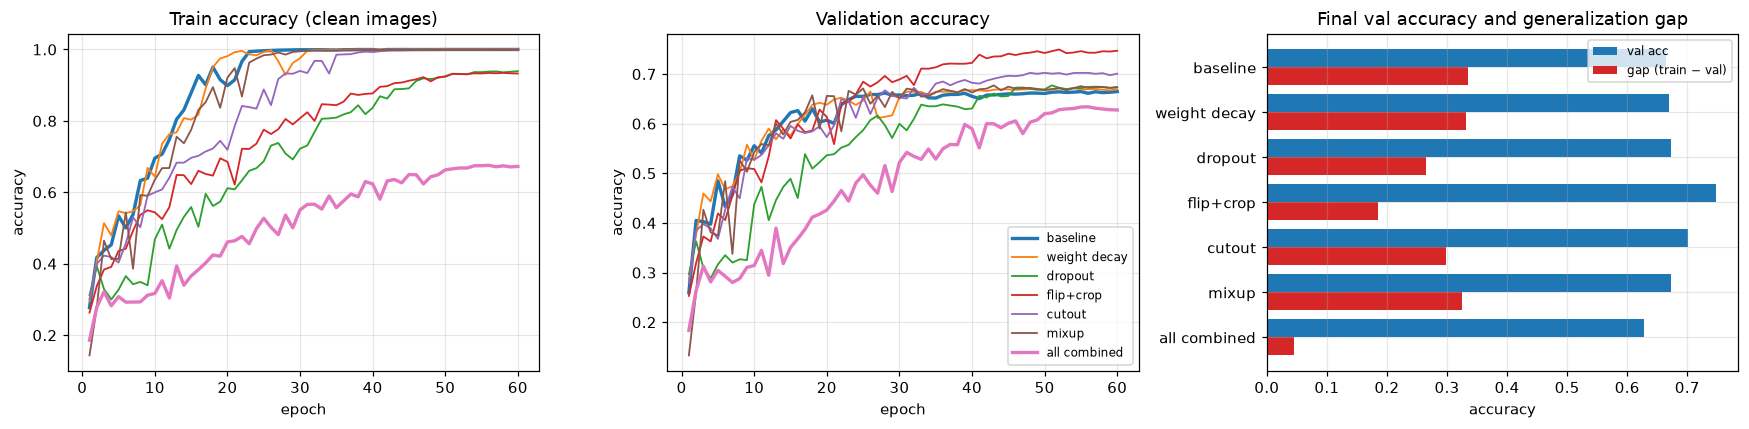

In [17]:
rows = []
for name, hh in res3a.items():
    rows.append({"setting": name, "train acc": hh["train_acc"][-1], "val acc": hh["val_acc"][-1],
                 "gap (train − val)": hh["train_acc"][-1] - hh["val_acc"][-1], "best val acc": max(hh["val_acc"])})
t3a = pd.DataFrame(rows).set_index("setting")
display(t3a.style.format("{:.3f}").highlight_max(subset=["val acc", "best val acc"], props="font-weight:bold")
        .highlight_min(subset=["gap (train − val)"], props="font-weight:bold"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, hh in res3a.items():
    ep = np.arange(1, len(hh["val_acc"]) + 1)
    lw = 2.2 if name in ("baseline", "all combined") else 1.2
    ax[0].plot(ep, hh["train_acc"], lw=lw, label=name)
    ax[1].plot(ep, hh["val_acc"], lw=lw, label=name)
ax[0].set(xlabel="epoch", ylabel="accuracy", title="Train accuracy (clean images)")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")
ax[1].legend(fontsize=8)
yy = np.arange(len(t3a))
ax[2].barh(yy - 0.2, t3a["val acc"], height=0.4, color="C0", label="val acc")
ax[2].barh(yy + 0.2, t3a["gap (train − val)"], height=0.4, color="C3", label="gap (train − val)")
ax[2].set_yticks(yy, t3a.index); ax[2].invert_yaxis()
ax[2].set(xlabel="accuracy", title="Final val accuracy and generalization gap"); ax[2].legend(fontsize=8)
plt.tight_layout(); savefig("t3a_regularization"); plt.show()

**Interpretation.**

| setting | train acc | val acc | gap |
|---|---|---|---|
| baseline | 100.0 % | 66.5 % | 33.5 |
| weight decay | 100.0 % | 66.9 % | 33.1 |
| dropout | 93.9 % | 67.3 % | 26.6 |
| **flip+crop** | 93.3 % | **74.7 %** | 18.6 |
| cutout | 99.9 % | 70.1 % | 29.8 |
| mixup | 99.9 % | 67.4 % | 32.5 |
| all combined | 67.3 % | 62.8 % | **4.5** |

* **Baseline:** with only 500 images per class, the 670k-parameter BN-CNN reaches **100 % training accuracy by about epoch 25**, while validation accuracy plateaus at 66.5 %. A 33-point gap means the network has memorized the training set.
* **Weight decay** ($10^{-3}$) has almost no effect (+0.4 points). With batch norm, the scale of the conv weights does not change the function, so L2 mainly changes the effective learning rate rather than constraining capacity. In this 60-epoch run it did not stop memorization.
* **Dropout** (on the FC head) slows memorization (training accuracy 94 %) and reduces the gap to 27 points, but improves validation accuracy by only 0.8 points.
* **Flip+crop** is by far the best single method: **+8.2 points** of validation accuracy and the gap reduced to 19 points.
  * It creates label-preserving variants that match real invariances of natural images, which effectively enlarges the training set.
* **Cutout** (+3.6 points) also helps, but the network still fits the training images almost perfectly.
* **Mixup** ($\alpha=0.4$) gives only +0.9 points. Its training accuracy on clean images is still 99.9 %, so with a mild $\alpha$ and a strong network it barely regularizes in this setting.
* **All combined** gives the **smallest gap (4.5 points)** but the **lowest validation accuracy (62.8 %)**: it **underfits**.
  * Training accuracy reaches only 67 % and is still rising at epoch 60, so the stacked regularizers make the problem too hard for this budget.
  * Regularization trades variance for bias. Combining everything needs a longer schedule, or weaker individual settings.
* **Conclusion:** on small datasets, data augmentation, particularly geometric augmentation, is the most effective regularizer. A small gap alone does not mean good generalization if the model underfits.

## 3(b) Plain vs residual networks of depth $6n+2$

The networks follow the CIFAR ResNet design of He et al. (2016):
* a 3×3 conv with 16 channels;
* **three stages** of $n$ basic blocks with **16 / 32 / 64 channels**, where each block is conv-BN-ReLU-conv-BN with $(+\text{shortcut})$ then ReLU, and stride 2 at the start of stages 2 and 3;
* **global average pooling** and a 10-way FC layer;
* **Kaiming-normal** initialization.

| depth | $n$ |
|---|---|
| 8 | 1 |
| 20 | 3 |
| 56 | 9 |

**The only difference between the two families is the identity shortcut.** Where the shape changes, the shortcut subsamples and zero-pads the channels (He et al.'s option A), so it adds **no parameters**. Plain and residual networks of the same depth therefore have identical parameter counts.

**Training (same recipe for all six networks):**
* 45k training images with flip+crop augmentation.
* SGD with momentum 0.9, learning rate 0.1 with a 2-epoch linear warm-up then cosine decay, weight decay $10^{-4}$, batch size 128.
* 30 epochs with mixed precision.

In [18]:
def conv3x3(cin, cout, stride=1):
    return nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)

class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1, self.bn1 = conv3x3(cin, cout, stride), nn.BatchNorm2d(cout)
        self.conv2, self.bn2 = conv3x3(cout, cout), nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin
    def shortcut(self, x):   # option A: parameter-free identity / subsample + zero-pad channels
        if self.stride != 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra:
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
        return x
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)

class CifarNet(nn.Module):
    def __init__(self, depth, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(conv3x3(3, widths[0]), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, cin = [], widths[0]
        for i, w in enumerate(widths):
            for j in range(n):
                blocks.append(BasicBlock(cin, w, 2 if (j == 0 and i > 0) else 1, residual))
                cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():   # Kaiming init for convolutions; the FC layer keeps PyTorch's default
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))

DEPTHS = [8, 20, 56]
display(pd.DataFrame({"depth": DEPTHS,
                      "plain params": [f"{n_params(CifarNet(d, False)):,}" for d in DEPTHS],
                      "residual params": [f"{n_params(CifarNet(d, True)):,}" for d in DEPTHS]}).style.hide(axis="index"))

depth,plain params,residual params
8,"75,290","75,290"
20,"269,722","269,722"
56,"853,018","853,018"


In [19]:
def run_depth(depth, residual):
    set_seed()
    model = CifarNet(depth, residual).to(DEVICE).to(memory_format=torch.channels_last)
    opt = MySGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    return train(model, opt, EPOCHS["t3b"], Xtr, Ytr, Xva, Yva, bs=128, aug=flip_crop,
                 sched="warmup_cosine", amp=True, log_every=10)

res3b = {}
for depth in DEPTHS:
    for residual in (False, True):
        tag = f"{'residual' if residual else 'plain'}-{depth}"
        print(tag)
        res3b[tag] = cached(f"t3b_{tag}", lambda d=depth, r=residual: run_depth(d, r))

plain-8


  epoch  10/30  train loss 0.652  train acc 0.775  val acc 0.732  (16s)


  epoch  20/30  train loss 0.461  train acc 0.841  val acc 0.824  (32s)


  epoch  30/30  train loss 0.381  train acc 0.870  val acc 0.848  (48s)
residual-8


  epoch  10/30  train loss 0.672  train acc 0.764  val acc 0.706  (17s)


...

  epoch  20/30  train loss 0.950  train acc 0.662  val acc 0.646  (168s)


  epoch  30/30  train loss 0.685  train acc 0.761  val acc 0.757  (253s)
residual-56


  epoch  10/30  train loss 0.456  train acc 0.842  val acc 0.822  (90s)


  epoch  20/30  train loss 0.218  train acc 0.923  val acc 0.877  (179s)


  epoch  30/30  train loss 0.090  train acc 0.970  val acc 0.899  (268s)


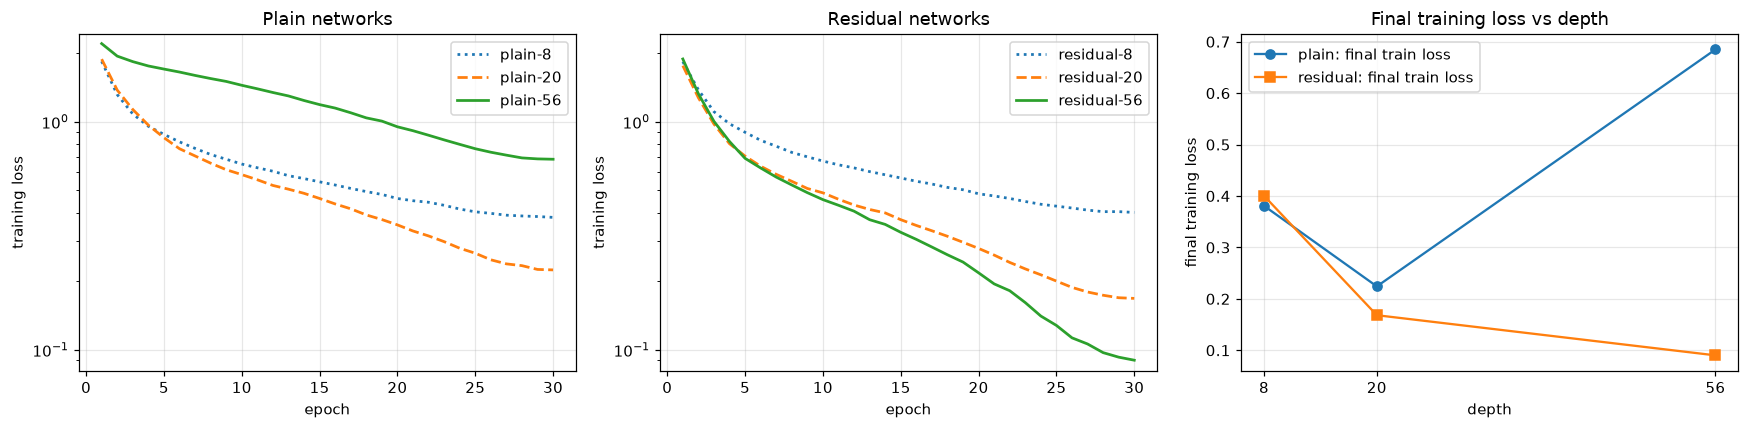

,final train loss,final train acc,final val acc,time (min)
network,,,,
plain-8,0.381,0.870,0.848,0.794
residual-8,0.400,0.863,0.845,0.872
plain-20,0.224,0.924,0.875,1.628
residual-20,0.168,0.942,0.890,1.740
plain-56,0.685,0.761,0.757,4.217
residual-56,0.090,0.970,0.899,4.467


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
styles = {8: ":", 20: "--", 56: "-"}
for fam, a in zip(["plain", "residual"], ax[:2]):
    for d in DEPTHS:
        hh = res3b[f"{fam}-{d}"]
        a.plot(np.arange(1, len(hh["train_loss"]) + 1), hh["train_loss"], styles[d], lw=1.8, label=f"{fam}-{d}")
    a.set(xlabel="epoch", ylabel="training loss", title=f"{fam.capitalize()} networks", yscale="log"); a.legend()
ymin = min(min(h["train_loss"]) for h in res3b.values() if h["train_loss"])
ymax = max(max(h["train_loss"]) for h in res3b.values() if h["train_loss"])
for a in ax[:2]:
    a.set_ylim(ymin * 0.9, ymax * 1.1)
for fam, mk in [("plain", "o-"), ("residual", "s-")]:
    ax[2].plot(DEPTHS, [res3b[f"{fam}-{d}"]["train_loss"][-1] for d in DEPTHS], mk, label=f"{fam}: final train loss")
ax[2].set(xlabel="depth", ylabel="final training loss", xticks=DEPTHS, title="Final training loss vs depth"); ax[2].legend()
plt.tight_layout(); savefig("t3b_plain_vs_residual"); plt.show()

display(pd.DataFrame([{"network": k, "final train loss": v["train_loss"][-1], "final train acc": v["train_acc"][-1],
                       "final val acc": v["val_acc"][-1], "time (min)": v["time"] / 60} for k, v in res3b.items()])
        .set_index("network").style.format("{:.3f}"))

**Interpretation.**

| depth | plain: train loss / val acc | residual: train loss / val acc |
|---|---|---|
| 8 | 0.381 / 84.8 % | 0.400 / 84.5 % |
| 20 | 0.224 / 87.5 % | 0.168 / 89.0 % |
| 56 | **0.685 / 75.7 %** | **0.090 / 89.9 %** |

* **Plain networks show the degradation problem.**
  * Going from 8 to 20 layers helps, but **plain-56 is far worse than plain-20**: its training loss is 3× higher, and its curve stays above plain-20's from the very first epoch.
  * Because the deeper network is worse on the *training* set, this is an **optimization failure, not overfitting**. A 56-layer network could in principle copy the 20-layer solution and set its extra layers to the identity, but SGD does not find such a solution.
  * In a first attempt without learning-rate warm-up, plain-56 even diverged to NaN in epoch 1, while the residual networks did not. This is another sign of its much harder optimization landscape.
* **Residual networks fix it: deeper is better.**
  * The final training loss falls monotonically with depth, 0.400 → 0.168 → 0.090.
  * Residual-56 is the best of the six networks (89.9 % validation accuracy).
* **Why the shortcut helps:**
  * Each block only learns a residual $F(x)$ added to $x$, so the identity is the easy default ($F=0$).
  * The Jacobian of a block is $I+\partial F/\partial x$, so gradients have a direct path to the early layers instead of being multiplied through 54 conv-BN-ReLU stages.
* **Shallow networks:** at depth 8 the two families are practically identical, with plain slightly ahead. There are too few layers for the optimization difficulty to appear, and the benefit of shortcuts grows with depth.
* Both families have *identical* parameter counts (75k / 270k / 853k), so every difference comes from the shortcut alone.

---
# Task 4: Best CNN with ≤ 500k parameters and ≤ 20 epochs

**Design.** A compact ResNet:
* a 3×3 stem with 32 channels;
* three stages of **2 basic blocks** with **32 / 64 / 96 channels**, stride 2 at the start of stages 2 and 3;
* 1×1 projection shortcuts where the shape changes;
* global average pooling and an FC layer.

That makes 14 weight layers and about **0.48M parameters**. Projection shortcuts are used here (instead of option A as in 3(b)) because they cost only about 8k parameters.

**Training recipe (the "full" configuration):**
* 20 epochs, batch size 128.
* SGD with Nesterov momentum 0.9 and a **one-cycle** learning-rate schedule (peak 0.1, warm-up for 25 % of training).
* Weight decay $5\times10^{-4}$.
* **Label smoothing** 0.1.
* Augmentation: flip+crop + cutout 16×16.
* Mixed precision.

**Tuning:** only on the 5k validation split. The final model is the configuration with the best validation accuracy, and the **test set is evaluated exactly once**, at the very end.

**Result:** the selected configuration turned out to be the full recipe *without cutout*, reaching 90.78 % validation and **91.23 % test accuracy** (details below).

In [21]:
class Block4(nn.Module):
    def __init__(self, cin, cout, stride, residual=True):
        super().__init__()
        self.conv1, self.bn1 = conv3x3(cin, cout, stride), nn.BatchNorm2d(cout)
        self.conv2, self.bn2 = conv3x3(cout, cout), nn.BatchNorm2d(cout)
        self.residual = residual
        self.proj = None
        if residual and (stride != 1 or cin != cout):
            self.proj = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + (x if self.proj is None else self.proj(x))
        return F.relu(out)

class Net4(nn.Module):
    def __init__(self, widths=(32, 64, 96), blocks=(2, 2, 2), residual=True):
        super().__init__()
        self.stem = nn.Sequential(conv3x3(3, widths[0]), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for i, (w, nb) in enumerate(zip(widths, blocks)):
            for j in range(nb):
                layers.append(Block4(cin, w, 2 if (j == 0 and i > 0) else 1, residual))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.layers(self.stem(x)), 1).flatten(1))

print(f"Net4 parameters: {n_params(Net4()):,}  (limit 500,000)")
assert n_params(Net4()) <= 500_000

Net4 parameters: 481,962  (limit 500,000)


**Ablation.** Each variant changes exactly one design choice of the full configuration:

| variant | change |
|---|---|
| no shortcut | plain network (shortcuts removed) |
| no augmentation | no flip, crop or cutout |
| no cutout | flip+crop only |
| no weight decay | $\lambda=0$ |
| AdamW | AdamW instead of SGD-Nesterov (peak lr $2\times10^{-3}$, decoupled weight decay 0.05, same one-cycle schedule) |
| no label smoothing | plain cross-entropy |

In [22]:
FULL = dict(residual=True, flipcrop=True, cutout=True, wd=5e-4, opt="sgd", ls=0.1)
VARIANTS = {
    "full": {},
    "no shortcut": dict(residual=False),
    "no augmentation": dict(flipcrop=False, cutout=False),
    "no cutout": dict(cutout=False),
    "no weight decay": dict(wd=0.0),
    "AdamW": dict(opt="adamw"),
    "no label smoothing": dict(ls=0.0),
}

def run4(name, overrides):
    cfg = {**FULL, **overrides}
    set_seed()
    model = Net4(residual=cfg["residual"]).to(DEVICE).to(memory_format=torch.channels_last)
    if cfg["opt"] == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=cfg["wd"])
    else:
        opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.05 if cfg["wd"] > 0 else 0.0)
    aug = compose(flip_crop if cfg["flipcrop"] else None, cutout if cfg["cutout"] else None)
    h = train(model, opt, EPOCHS["t4"], Xtr, Ytr, Xva, Yva, bs=128, aug=aug, sched="onecycle",
              amp=True, label_smoothing=cfg["ls"], log_every=5)
    torch.save(model.state_dict(), os.path.join(RESULTS, f"t4_{name.replace(' ', '_')}.pth"))
    h["params"] = n_params(model)
    return h

res4 = {}
for name, ov in VARIANTS.items():
    print(name)
    res4[name] = cached(f"t4_{name.replace(' ', '_')}", lambda name=name, ov=ov: run4(name, ov))

full


  epoch   5/20  train loss 1.218  train acc 0.684  val acc 0.715  (14s)


  epoch  10/20  train loss 1.038  train acc 0.768  val acc 0.766  (28s)


  epoch  15/20  train loss 0.932  train acc 0.817  val acc 0.844  (41s)


  epoch  20/20  train loss 0.797  train acc 0.879  val acc 0.898  (55s)
no shortcut


...

  epoch  20/20  train loss 0.818  train acc 0.872  val acc 0.894  (56s)
no label smoothing


  epoch   5/20  train loss 0.897  train acc 0.684  val acc 0.643  (13s)


  epoch  10/20  train loss 0.666  train acc 0.770  val acc 0.746  (27s)


  epoch  15/20  train loss 0.526  train acc 0.817  val acc 0.833  (40s)


  epoch  20/20  train loss 0.343  train acc 0.880  val acc 0.902  (54s)


,params,final val acc,best val acc,Δ final val vs full,time (min)
variant,,,,,
full,"481,962",0.8980,0.8980,+0.0000,0.9
no shortcut,"473,450",0.8954,0.8954,-0.0026,0.8
no augmentation,"481,962",0.8622,0.8632,-0.0358,0.9
no cutout,"481,962",0.9078,0.9078,+0.0098,0.9
no weight decay,"481,962",0.8812,0.8822,-0.0168,0.9
AdamW,"481,962",0.8940,0.8944,-0.0040,0.9
no label smoothing,"481,962",0.9022,0.9022,+0.0042,0.9


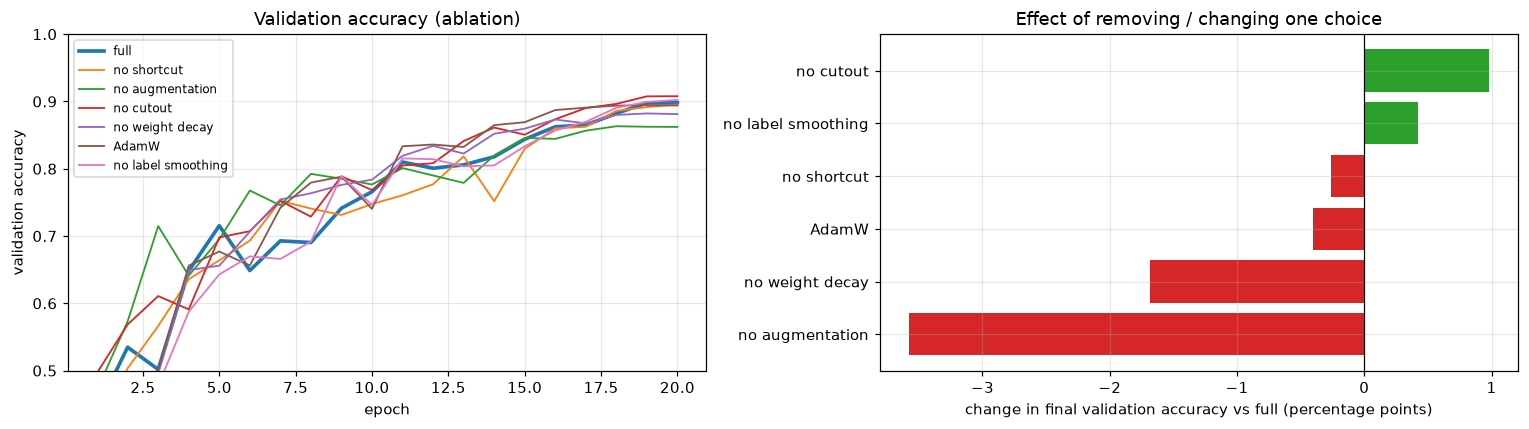

In [23]:
full_best = max(res4["full"]["val_acc"])
abl = pd.DataFrame([{"variant": k, "params": v["params"], "final val acc": v["val_acc"][-1],
                     "best val acc": max(v["val_acc"]), "Δ final val vs full": v["val_acc"][-1] - res4["full"]["val_acc"][-1],
                     "time (min)": v["time"] / 60} for k, v in res4.items()]).set_index("variant")
display(abl.style.format({"params": "{:,}", "final val acc": "{:.4f}", "best val acc": "{:.4f}",
                          "Δ final val vs full": "{:+.4f}", "time (min)": "{:.1f}"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, hh in res4.items():
    ep = np.arange(1, len(hh["val_acc"]) + 1)
    ax[0].plot(ep, hh["val_acc"], lw=2.4 if name == "full" else 1.2, label=name)
ax[0].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy (ablation)", ylim=(0.5, 1.0))
ax[0].legend(fontsize=8)
d = abl["Δ final val vs full"].drop("full").sort_values()
ax[1].barh(d.index, d.values * 100, color=["C3" if v < 0 else "C2" for v in d.values])
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set(xlabel="change in final validation accuracy vs full (percentage points)", title="Effect of removing / changing one choice")
plt.tight_layout(); savefig("t4_ablation"); plt.show()

### Final model and the single test-set evaluation
The final configuration is the variant with the highest **final validation accuracy**. Its trained weights are loaded and evaluated on the 10k test set **once**. The result is cached, so re-running the notebook does not evaluate the test set again.

In [24]:
final_name = abl["final val acc"].idxmax()
print(f"selected on validation: '{final_name}'  (val acc {abl.loc[final_name, 'final val acc']:.4f}, "
      f"{int(abl.loc[final_name, 'params']):,} params, {EPOCHS['t4']} epochs)")

def test_once():
    cfg = {**FULL, **VARIANTS[final_name]}
    model = Net4(residual=cfg["residual"]).to(DEVICE).to(memory_format=torch.channels_last)
    model.load_state_dict(torch.load(os.path.join(RESULTS, f"t4_{final_name.replace(' ', '_')}.pth"),
                                     map_location=DEVICE))
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X_test), 1000):
            preds.append(model(X_test[i:i + 1000].to(DEVICE)).argmax(1).cpu())
    preds = torch.cat(preds)
    return {"model": final_name, "test_acc": (preds == Y_test).float().mean().item(), "preds": preds.tolist()}

test_res = cached("t4_TEST_EVALUATED_ONCE", test_once)
print(f"TEST ACCURACY of the final model: {test_res['test_acc']:.4f}")

selected on validation: 'no cutout'  (val acc 0.9078, 481,962 params, 20 epochs)


TEST ACCURACY of the final model: 0.9123


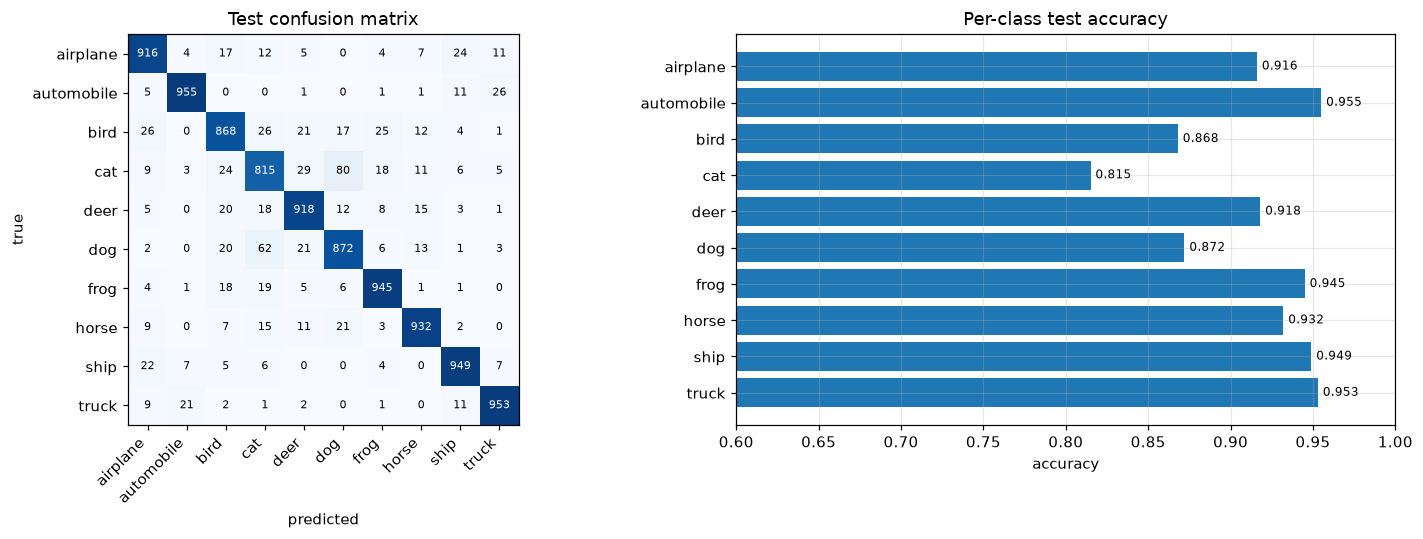

In [25]:
preds = np.array(test_res["preds"]); yt = Y_test.numpy()
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (yt, preds), 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if i == j else "black")
ax[0].set_xticks(range(10), CLASSES, rotation=45, ha="right"); ax[0].set_yticks(range(10), CLASSES)
ax[0].set(xlabel="predicted", ylabel="true", title="Test confusion matrix"); ax[0].grid(False)
per_class = cm.diagonal() / cm.sum(1)
ax[1].barh(CLASSES[::-1], per_class[::-1], color="C0"); ax[1].set_xlim(0.6, 1.0)
for i, v in enumerate(per_class[::-1]):
    ax[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
ax[1].set(xlabel="accuracy", title="Per-class test accuracy")
plt.tight_layout(); savefig("t4_test_confusion"); plt.show()

**Interpretation.**
* **Ablation** (final validation accuracy, full configuration = 89.80 %):

| change | val acc | Δ vs full | finding |
|---|---|---|---|
| no augmentation | 86.22 % | **−3.58** | Most important choice. Training accuracy hits 100 % by epoch 20, a clear overfit. |
| no weight decay | 88.12 % | **−1.68** | Second most important. With BN, weight decay keeps the weight norms small and so the effective learning rate high, which helps both optimization and generalization. |
| AdamW | 89.40 % | −0.40 | Competitive but slightly below well-tuned SGD-Nesterov with one-cycle, a common result for CNNs on CIFAR. |
| no shortcut | 89.54 % | −0.26 | Small effect at only 14 layers, consistent with 3(b), where shortcuts mattered little at depth 8–20 and a lot at depth 56. |
| no label smoothing | 90.22 % | **+0.42** | Smoothing *hurt* slightly in this budget. |
| **no cutout** | **90.78 %** | **+0.98** | Cutout *hurt*: with it, training accuracy is only 87.9 % versus 95.3 % without, so the model underfits in 20 epochs. |

* **Regularizers in a short budget:** cutout and label smoothing are regularizers that typically pay off in long schedules (hundreds of epochs). With only 20 epochs, the model is limited more by under-training than by overfitting, so adding them costs accuracy. This is the same bias–variance trade-off seen in 3(a)'s "all combined" result.
* **Final model:** the variant chosen on validation is **"no cutout"**: ResNet-14, 481,962 parameters, 20 epochs, SGD-Nesterov with one-cycle, flip+crop, weight decay and label smoothing. Its **single test evaluation gives 91.23 %**.
  * This is within half a point of its validation accuracy (90.78 %), which is within the sampling noise of a 5k validation set (about ±0.4 points).
  * The model selection therefore did not overfit the validation split.
* **Confusion matrix:**
  * Errors concentrate on visually similar classes.
  * **Cat** is the hardest class (81.5 %). Its largest confusion is with **dog**: 80 cats were predicted as dogs and 62 dogs as cats.
  * Other confusions are bird ↔ other animals, automobile ↔ truck (26 / 21) and airplane ↔ ship (24 / 22).
  * Vehicles are easiest: automobile 95.5 %, truck 95.3 %, ship 94.9 %.

---
# Conclusion

* **Task 1:**
  * The from-scratch Linear / ReLU / softmax cross-entropy layers match autograd to about $10^{-17}$ and centred finite differences to about $10^{-9}$.
  * The MLP on raw pixels reaches 51.1 % validation accuracy and overfits after about 8 epochs.
  * In a 10-layer network, sigmoid gradients shrink by about $10^{5}$ from output to input, while ReLU with He initialization keeps them within a factor of about 3.
* **Task 2:**
  * The custom SGD-momentum and Adam reproduce `torch.optim` exactly (bit-for-bit for SGD, within $4\times10^{-16}$ for Adam).
  * On the ill-conditioned quadratic, momentum and Adam reach an objective about 100–250× lower than gradient descent in 100 steps.
  * On the CNN, each optimizer works well only within about one decade of learning rate: Adam at $10^{-3}$ (75.1 %), momentum at $10^{-2}$ (74.9 %), SGD at $10^{-1}$ (68.0 %).
* **Task 3:**
  * With 5k images, flip+crop is the most effective regularizer (+8.2 points). Stacking every regularizer gives the smallest gap but underfits.
  * Plain-56 is far worse than plain-20 (the degradation problem), while residual-56 is the best network (89.9 %): shortcuts make depth usable.
* **Task 4:** a 482k-parameter ResNet-14 trained for 20 epochs with one-cycle SGD-Nesterov, flip+crop, weight decay and label smoothing reaches **91.23 % test accuracy**.
  * The ablation shows that augmentation and weight decay matter most.
  * Cutout and label smoothing do not pay off in such a short schedule.

**AI tool acknowledgement:** Claude (Anthropic) was used as a coding assistant to write and debug the code in this notebook and to help run the experiments on the lab GPU server. I have reviewed and understood all of the code and the results.